In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import tensorflow as tf
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))
# physical_devices = tf.config.list_physical_devices('GPU')
# tf.config.experimental.set_memory_growth(physical_devices[0], True)
gpus = tf.config.list_physical_devices('GPU')
if gpus:
  # Restrict TensorFlow to only allocate 1GB of memory on the first GPU
  try:
    tf.config.set_logical_device_configuration(
        gpus[0],
        [tf.config.LogicalDeviceConfiguration(memory_limit=39936)])
    logical_gpus = tf.config.list_logical_devices('GPU')
    print(len(gpus), "Physical GPUs,", len(logical_gpus), "Logical GPUs")
  except RuntimeError as e:
    # Virtual devices must be set before GPUs have been initialized
    print(e)

Num GPUs Available:  1
1 Physical GPUs, 1 Logical GPUs


In [ ]:
import os
import time
import datetime
import matplotlib.pyplot as plt
import numpy as np
from numpy.random import randint
from os import listdir
# import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator, img_to_array, array_to_img, load_img
from tensorflow.keras import layers
from numpy import asarray, savez_compressed
from tensorflow.keras import Input
from numpy import load, zeros, ones
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.initializers import RandomNormal
from tensorflow.keras.layers import Conv2D, UpSampling2D, Activation, Dense, Reshape, Flatten, MaxPooling2D
from tensorflow.keras.layers import Concatenate, Dropout, BatchNormalization, LeakyReLU, Conv2DTranspose, ReLU, GlobalAveragePooling2D
from tensorflow.keras import backend as K
from sklearn.model_selection import train_test_split
from sklearn.model_selection import ParameterGrid
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from keras.models import Sequential
from tensorflow.keras.losses import MeanSquaredError, BinaryCrossentropy
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

In [ ]:
K.clear_session()

In [ ]:
# Function to load and preprocess images
def load_and_preprocess_images(data_path, folder):
    images = []
    folder_path = os.path.join(data_path, folder)

    # Sort the filenames to ensure consistent order
    filenames = sorted(os.listdir(folder_path))

    for filename in sorted(os.listdir(folder_path)):
        img_path = os.path.join(folder_path, filename)
        img = load_img(img_path, target_size=(400, 600))  # Resize images as needed
        img_array = img_to_array(img) / 255.0  # Normalize pixel values to the range [0, 1]
        images.append(img_array)

    return np.array(images)

data_path = '/content/drive/MyDrive/LOL_dataset/lol_dataset/'

train_low_light_images, val_low_light_images = train_test_split(load_and_preprocess_images(data_path, 'our485/low'), test_size=0.2, random_state=42)
train_normal_light_images, val_normal_light_images = train_test_split(load_and_preprocess_images(data_path, 'our485/high'), test_size=0.2, random_state=42)

test_low_light_images = load_and_preprocess_images(data_path, 'eval15/low')
test_normal_light_images = load_and_preprocess_images(data_path, 'eval15/high')


In [ ]:
# Print shapes of the split datasets
print("Shape of train_images:", train_low_light_images.shape)
print("Shape of val_images:", val_low_light_images.shape)
print("Shape of test_images:", test_low_light_images.shape)

Shape of train_images: (388, 400, 600, 3)
Shape of val_images: (97, 400, 600, 3)
Shape of test_images: (15, 400, 600, 3)


In [ ]:
input_shape=((400, 600, 3))

In [ ]:
def generated_cnn_model_images(enhanced_images):
  # Visualize a few enhanced images
  num_visualize = 3
  for i in range(num_visualize):
      plt.figure(figsize=(12, 6))

      plt.subplot(1, 3, 1)
      plt.imshow(test_low_light_images[i])
      plt.title('Low Light Image')

      plt.subplot(1, 3, 2)
      plt.imshow(enhanced_images[i])
      plt.title('Enhanced Image')

      plt.subplot(1, 3, 3)
      plt.imshow(test_normal_light_images[i])
      plt.title('Ground Truth (Normal Light)')

      plt.show()

In [ ]:
K.clear_session()

In [ ]:
# Model 2: FMBCNN with Skip Connections
def build_fmbcnn_with_skip_connections():
    # Input layer
    inputs = Input(shape=input_shape)

    # Encoder (Downsampling)
    conv1 = Conv2D(64, kernel_size=3, strides=1, padding='same')(inputs)
    bn1 = BatchNormalization()(conv1)
    relu1 = Activation('relu')(bn1)
    skip_connection_1 = relu1

    conv2 = Conv2D(128, kernel_size=3, strides=2, padding='same')(relu1)
    bn2 = BatchNormalization()(conv2)
    relu2 = Activation('relu')(bn2)
    skip_connection_2 = relu2

    conv3 = Conv2D(256, kernel_size=3, strides=2, padding='same')(relu2)
    bn3 = BatchNormalization()(conv3)
    relu3 = Activation('relu')(bn3)

    # Feature Map Processing Layer
    up1 = UpSampling2D()(relu3)
    concat1 = Concatenate()([up1, skip_connection_2])
    conv_transpose = Conv2D(128, kernel_size=3, strides=1, padding='same')(concat1)
    bn4 = BatchNormalization()(conv_transpose)
    relu4 = Activation('relu')(bn4)

    # Decoder (Upsampling) with Skip Connections
    up2 = UpSampling2D()(relu4)
    concat2 = Concatenate()([up2, skip_connection_1])
    conv_transpose2 = Conv2D(64, kernel_size=3, strides=1, padding='same')(concat2)
    bn5 = BatchNormalization()(conv_transpose2)
    relu5 = Activation('relu')(bn5)

    # Output layer
    output = Conv2D(3, kernel_size=3, strides=1, padding='same', activation='sigmoid')(relu5)

    # Create the model
    model = Model(inputs=inputs, outputs=output)
    return model

In [ ]:
# Compile CNN model
def fmbcnn_with_skip_connections_model_compile(params):
  # Build the feed-forward denoising model
  denoising_model = build_fmbcnn_with_skip_connections()
  # Compile the model
  denoising_model.compile(optimizer=Adam(learning_rate=params['learning_rate']), loss='mse', metrics='accuracy')
  checkpoint_basic_cnn = ModelCheckpoint("/content/drive/MyDrive/fmbcnn_with_skip_connections_model.h5", save_best_only=True)
  # early_stopping_basic_cnn = EarlyStopping(patience=5, restore_best_weights=True)
  # Train the model
  history = denoising_model.fit(
      train_low_light_images, train_normal_light_images,  # Denoising autoencoder, input and output are the same
      epochs=params['epochs'],
      batch_size=params['batch_size'],
      validation_data=(val_low_light_images, val_normal_light_images),
      callbacks=[checkpoint_basic_cnn]
  )
  # Evaluate the model on the test set
  test_loss = denoising_model.evaluate(test_low_light_images, test_normal_light_images)

  enhanced_images = denoising_model.predict(test_low_light_images)
  generated_cnn_model_images(enhanced_images)

  return denoising_model

In [ ]:
# Function to evaluate the model with different hyperparameter combinations
def evaluate_fmbcnn_cnn_model_(train_images, val_images, params):
    # Build the denoising model
    fmbcnn_with_skip_connections_model = fmbcnn_with_skip_connections_model_compile(params)

    # Evaluate on validation set
    denoised_images = fmbcnn_with_skip_connections_model.predict(val_images)

    mse = MeanSquaredError()(val_images, denoised_images).numpy()
    psnr = peak_signal_noise_ratio(val_images[0], denoised_images[0], data_range=denoised_images[0].max())
    ssim_index = structural_similarity(val_images[0], denoised_images[0], multichannel=True)

    return {'params': params, 'mse': mse, 'psnr': psnr, 'ssim': ssim_index}

In [ ]:
K.clear_session()

Epoch 1/50
49/49 [==============================] - 12s 176ms/step - loss: 0.0346 - accuracy: 0.5520 - val_loss: 0.0515 - val_accuracy: 0.1503
Epoch 2/50
49/49 [==============================] - 7s 139ms/step - loss: 0.0243 - accuracy: 0.6030 - val_loss: 0.0540 - val_accuracy: 0.2765
Epoch 3/50
49/49 [==============================] - 7s 139ms/step - loss: 0.0235 - accuracy: 0.6206 - val_loss: 0.0564 - val_accuracy: 0.5438
Epoch 4/50
49/49 [==============================] - 7s 139ms/step - loss: 0.0218 - accuracy: 0.6408 - val_loss: 0.0540 - val_accuracy: 0.5550
Epoch 5/50
49/49 [==============================] - 7s 139ms/step - loss: 0.0224 - accuracy: 0.6449 - val_loss: 0.0551 - val_accuracy: 0.5549
Epoch 6/50
49/49 [==============================] - 7s 139ms/step - loss: 0.0214 - accuracy: 0.6452 - val_loss: 0.0536 - val_accuracy: 0.5473
Epoch 7/50
49/49 [==============================] - 7s 139ms/step - loss: 0.0213 - accuracy: 0.6556 - val_loss: 0.0525 - val_accuracy: 0.5575
Epoch

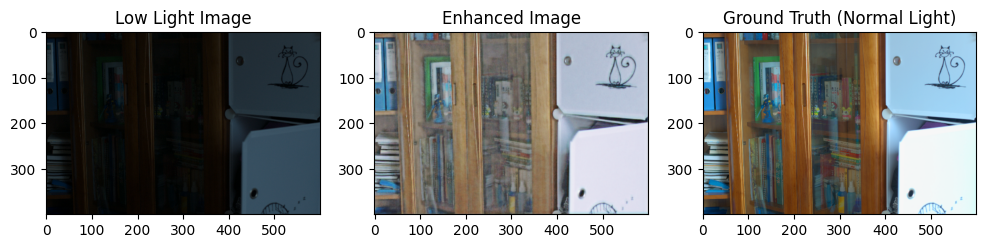

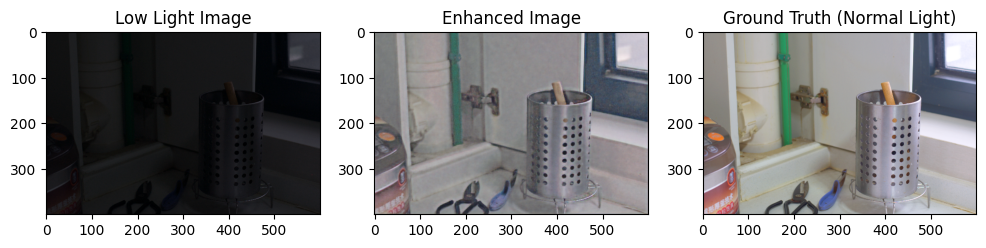

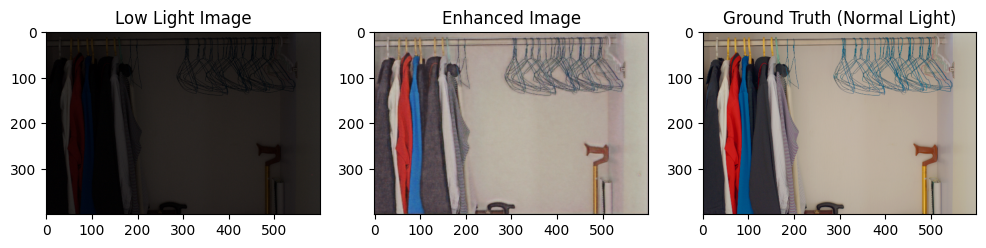

4/4 [==============================] - 23s 103ms/step


<ipython-input-32-c4099773d7ac>:11: FutureWarning: `multichannel` is a deprecated argument name for `structural_similarity`. It will be removed in version 1.0. Please use `channel_axis` instead.
  ssim_index = structural_similarity(val_images[0], denoised_images[0], multichannel=True)


Hyperparameters: {'batch_size': 8, 'epochs': 50, 'learning_rate': 0.0001}, MSE: 0.1834838092327118, PSNR: 6.4583304857366475, SSIM: 0.2686435282230377
Epoch 1/50
49/49 [==============================] - 11s 173ms/step - loss: 0.0299 - accuracy: 0.5686 - val_loss: 0.0575 - val_accuracy: 0.1324
Epoch 2/50
49/49 [==============================] - 7s 143ms/step - loss: 0.0250 - accuracy: 0.6556 - val_loss: 0.0564 - val_accuracy: 0.5665
Epoch 3/50
49/49 [==============================] - 7s 142ms/step - loss: 0.0233 - accuracy: 0.6715 - val_loss: 0.0512 - val_accuracy: 0.3283
Epoch 4/50
49/49 [==============================] - 7s 143ms/step - loss: 0.0233 - accuracy: 0.6727 - val_loss: 0.0478 - val_accuracy: 0.3513
Epoch 5/50
49/49 [==============================] - 7s 140ms/step - loss: 0.0245 - accuracy: 0.6719 - val_loss: 0.0499 - val_accuracy: 0.4813
Epoch 6/50
49/49 [==============================] - 7s 141ms/step - loss: 0.0231 - accuracy: 0.6490 - val_loss: 0.0536 - val_accuracy: 0.4

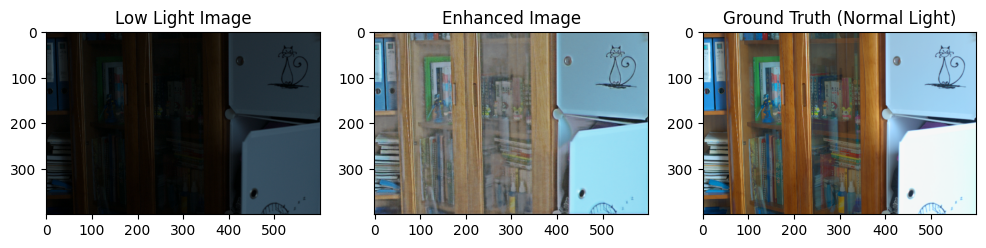

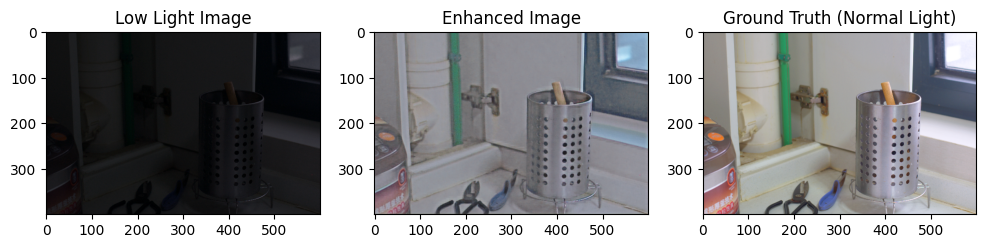

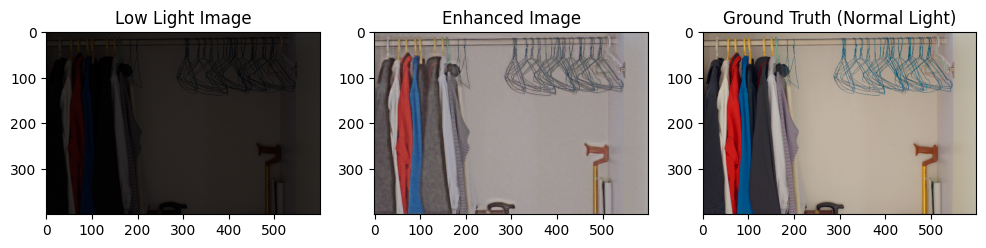

4/4 [==============================] - 1s 149ms/step
Hyperparameters: {'batch_size': 8, 'epochs': 50, 'learning_rate': 0.001}, MSE: 0.17574043571949005, PSNR: 6.805349756532097, SSIM: 0.2780470550060272
Epoch 1/50
49/49 [==============================] - 11s 169ms/step - loss: 0.0371 - accuracy: 0.4979 - val_loss: 0.2887 - val_accuracy: 0.5724
Epoch 2/50
49/49 [==============================] - 7s 141ms/step - loss: 0.0280 - accuracy: 0.5903 - val_loss: 0.0521 - val_accuracy: 0.2291
Epoch 3/50
49/49 [==============================] - 7s 141ms/step - loss: 0.0286 - accuracy: 0.5834 - val_loss: 0.0421 - val_accuracy: 0.4154
Epoch 4/50
49/49 [==============================] - 7s 141ms/step - loss: 0.0260 - accuracy: 0.6220 - val_loss: 0.0392 - val_accuracy: 0.5823
Epoch 5/50
49/49 [==============================] - 7s 141ms/step - loss: 0.0260 - accuracy: 0.5839 - val_loss: 0.0387 - val_accuracy: 0.6164
Epoch 6/50
49/49 [==============================] - 7s 139ms/step - loss: 0.0258 - acc

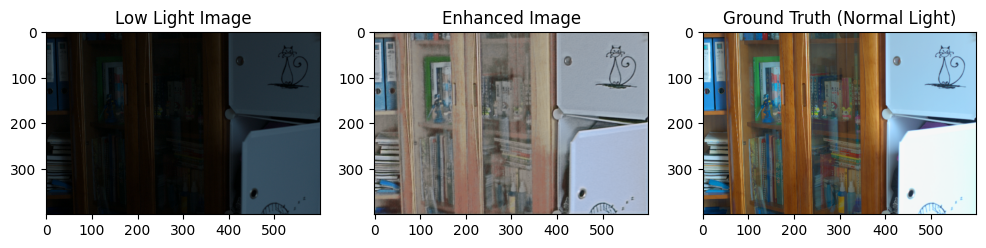

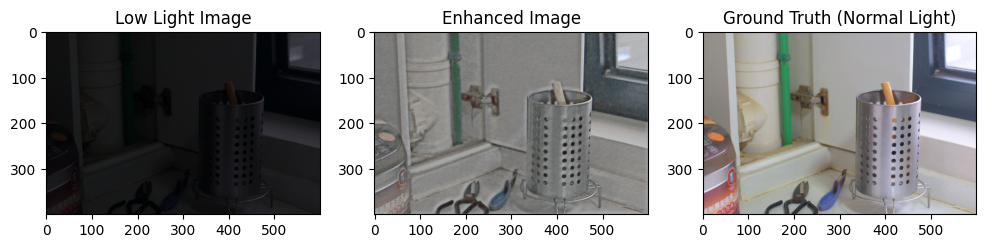

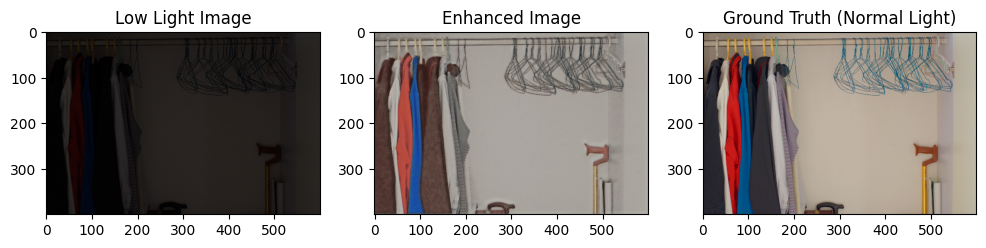

4/4 [==============================] - 1s 148ms/step
Hyperparameters: {'batch_size': 8, 'epochs': 50, 'learning_rate': 0.01}, MSE: 0.17052017152309418, PSNR: 6.6676612951357725, SSIM: 0.2821630537509918
Epoch 1/100
49/49 [==============================] - 11s 172ms/step - loss: 0.0321 - accuracy: 0.5577 - val_loss: 0.0518 - val_accuracy: 0.4219
Epoch 2/100
49/49 [==============================] - 7s 139ms/step - loss: 0.0252 - accuracy: 0.5824 - val_loss: 0.0532 - val_accuracy: 0.5440
Epoch 3/100
49/49 [==============================] - 7s 139ms/step - loss: 0.0237 - accuracy: 0.6149 - val_loss: 0.0532 - val_accuracy: 0.5712
Epoch 4/100
49/49 [==============================] - 7s 140ms/step - loss: 0.0224 - accuracy: 0.6329 - val_loss: 0.0521 - val_accuracy: 0.4061
Epoch 5/100
49/49 [==============================] - 7s 140ms/step - loss: 0.0221 - accuracy: 0.6305 - val_loss: 0.0519 - val_accuracy: 0.5732
Epoch 6/100
49/49 [==============================] - 8s 157ms/step - loss: 0.0217

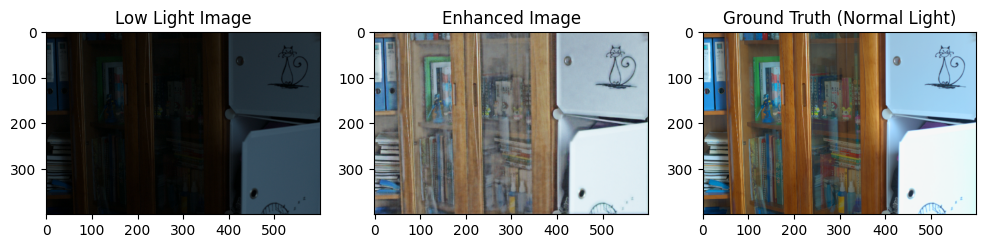

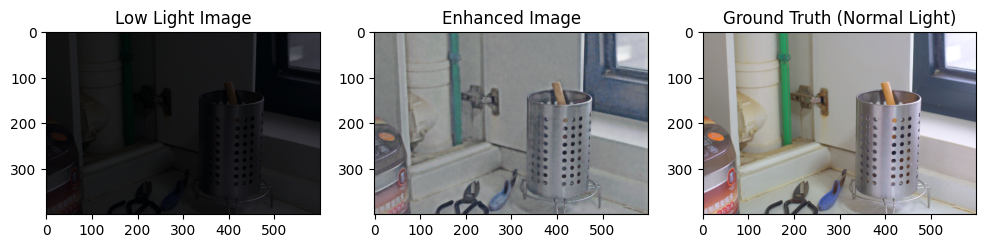

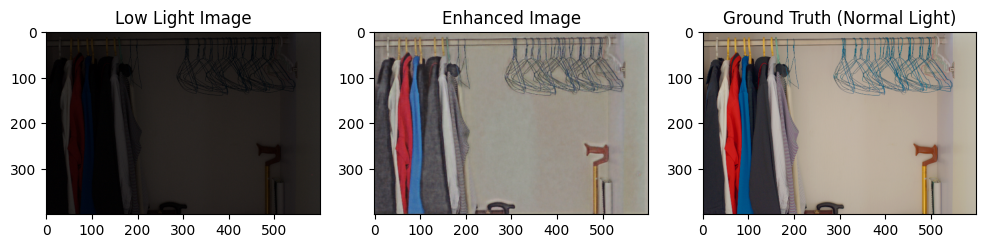

4/4 [==============================] - 1s 147ms/step
Hyperparameters: {'batch_size': 8, 'epochs': 100, 'learning_rate': 0.0001}, MSE: 0.17266260087490082, PSNR: 6.857312402924094, SSIM: 0.28453996777534485
Epoch 1/100
49/49 [==============================] - 11s 173ms/step - loss: 0.0280 - accuracy: 0.5960 - val_loss: 0.0518 - val_accuracy: 0.5604
Epoch 2/100
49/49 [==============================] - 7s 140ms/step - loss: 0.0248 - accuracy: 0.6382 - val_loss: 0.0524 - val_accuracy: 0.4847
Epoch 3/100
49/49 [==============================] - 7s 141ms/step - loss: 0.0239 - accuracy: 0.6477 - val_loss: 0.0518 - val_accuracy: 0.5608
Epoch 4/100
49/49 [==============================] - 7s 141ms/step - loss: 0.0244 - accuracy: 0.6729 - val_loss: 0.0555 - val_accuracy: 0.5735
Epoch 5/100
49/49 [==============================] - 8s 157ms/step - loss: 0.0234 - accuracy: 0.6828 - val_loss: 0.0508 - val_accuracy: 0.7083
Epoch 6/100
49/49 [==============================] - 7s 141ms/step - loss: 0.0

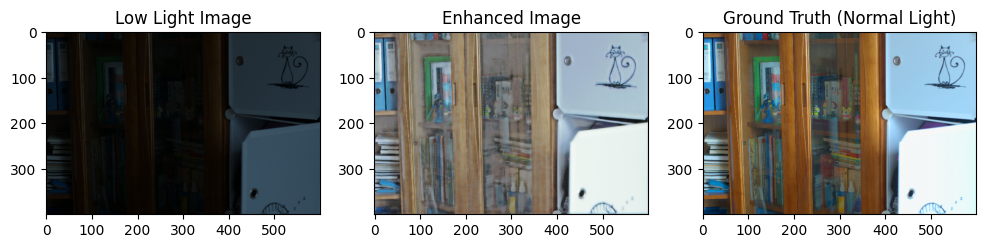

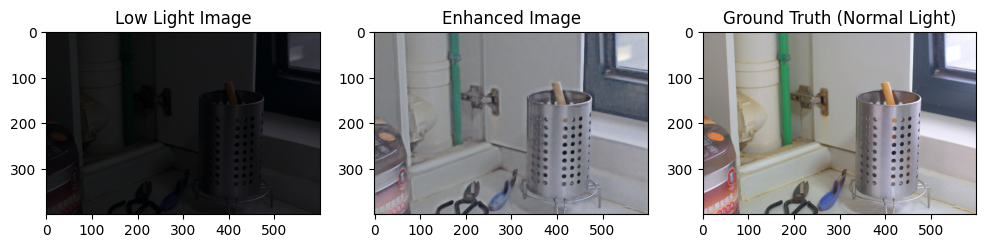

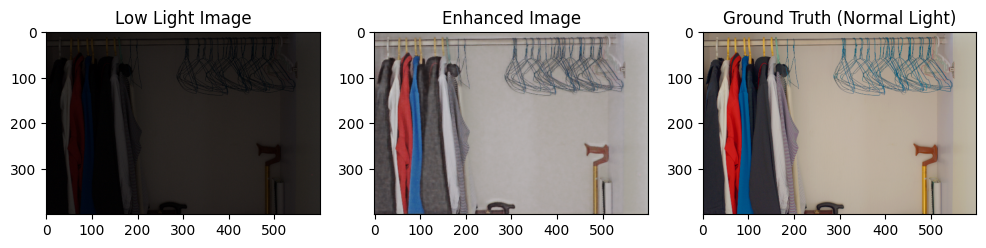

4/4 [==============================] - 0s 146ms/step
Hyperparameters: {'batch_size': 8, 'epochs': 100, 'learning_rate': 0.001}, MSE: 0.1810205727815628, PSNR: 6.40423729069139, SSIM: 0.272101491689682
Epoch 1/100
49/49 [==============================] - 12s 173ms/step - loss: 0.0329 - accuracy: 0.4865 - val_loss: 0.2332 - val_accuracy: 0.5615
Epoch 2/100
49/49 [==============================] - 7s 142ms/step - loss: 0.0301 - accuracy: 0.5933 - val_loss: 0.2172 - val_accuracy: 0.5580
Epoch 3/100
49/49 [==============================] - 7s 142ms/step - loss: 0.0275 - accuracy: 0.5633 - val_loss: 0.0474 - val_accuracy: 0.1250
Epoch 4/100
49/49 [==============================] - 7s 143ms/step - loss: 0.0275 - accuracy: 0.6136 - val_loss: 0.0398 - val_accuracy: 0.2702
Epoch 5/100
49/49 [==============================] - 7s 140ms/step - loss: 0.0271 - accuracy: 0.5951 - val_loss: 0.0408 - val_accuracy: 0.5501
Epoch 6/100
49/49 [==============================] - 8s 158ms/step - loss: 0.0263 -

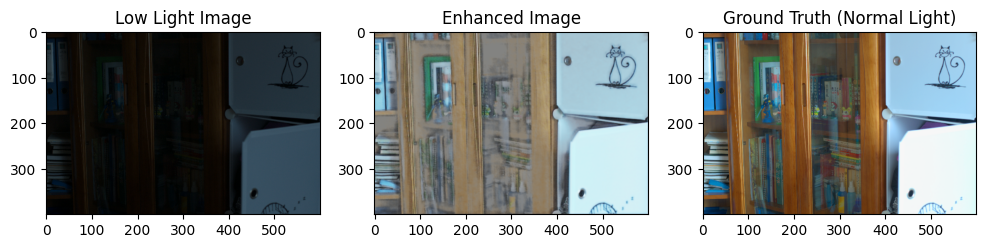

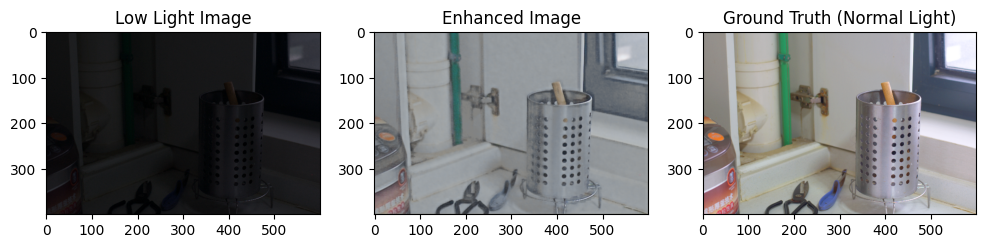

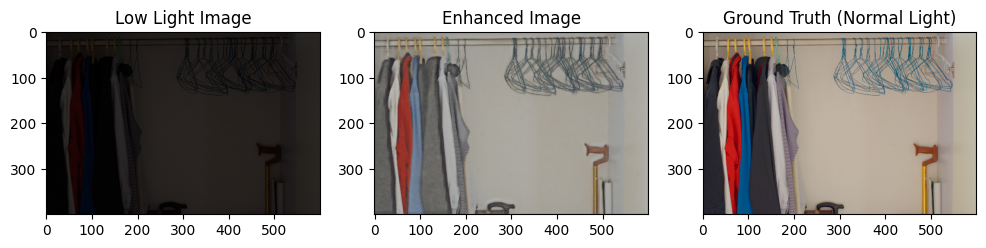

4/4 [==============================] - 1s 145ms/step
Hyperparameters: {'batch_size': 8, 'epochs': 100, 'learning_rate': 0.01}, MSE: 0.19922176003456116, PSNR: 6.087715219641351, SSIM: 0.26787737011909485
Epoch 1/50
25/25 [==============================] - 35s 790ms/step - loss: 0.0360 - accuracy: 0.4613 - val_loss: 0.0508 - val_accuracy: 0.4491
Epoch 2/50
25/25 [==============================] - 7s 270ms/step - loss: 0.0251 - accuracy: 0.5619 - val_loss: 0.0515 - val_accuracy: 0.5526
Epoch 3/50
25/25 [==============================] - 7s 269ms/step - loss: 0.0243 - accuracy: 0.6105 - val_loss: 0.0522 - val_accuracy: 0.5541
Epoch 4/50
25/25 [==============================] - 7s 269ms/step - loss: 0.0231 - accuracy: 0.6117 - val_loss: 0.0531 - val_accuracy: 0.5599
Epoch 5/50
25/25 [==============================] - 7s 269ms/step - loss: 0.0224 - accuracy: 0.6316 - val_loss: 0.0534 - val_accuracy: 0.5613
Epoch 6/50
25/25 [==============================] - 7s 269ms/step - loss: 0.0221 - ac

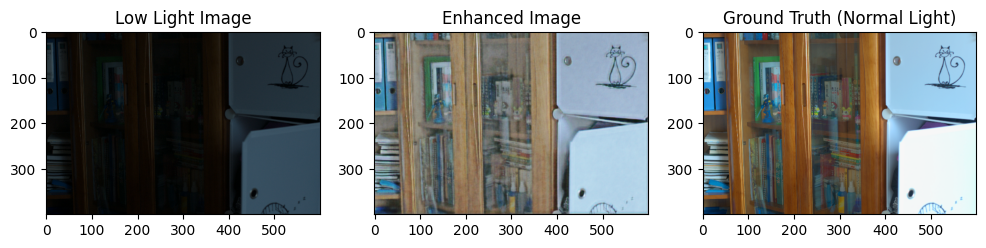

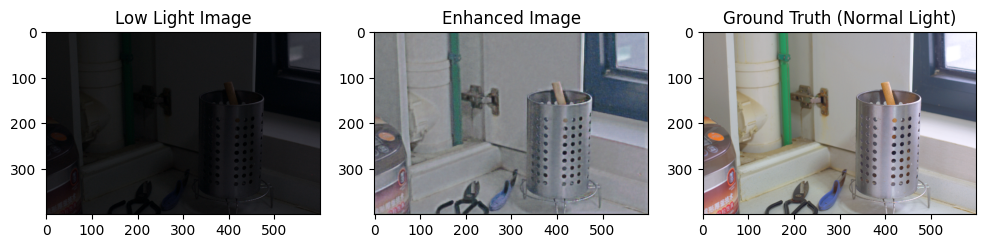

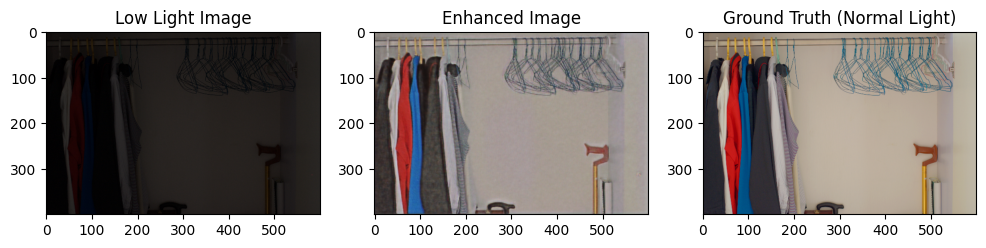

4/4 [==============================] - 1s 148ms/step
Hyperparameters: {'batch_size': 16, 'epochs': 50, 'learning_rate': 0.0001}, MSE: 0.1671321541070938, PSNR: 6.654472004242219, SSIM: 0.2793453335762024
Epoch 1/50
25/25 [==============================] - 11s 334ms/step - loss: 0.0339 - accuracy: 0.5427 - val_loss: 0.0507 - val_accuracy: 0.5639
Epoch 2/50
25/25 [==============================] - 7s 271ms/step - loss: 0.0274 - accuracy: 0.6104 - val_loss: 0.0528 - val_accuracy: 0.5633
Epoch 3/50
25/25 [==============================] - 7s 269ms/step - loss: 0.0248 - accuracy: 0.6346 - val_loss: 0.0511 - val_accuracy: 0.4703
Epoch 4/50
25/25 [==============================] - 7s 270ms/step - loss: 0.0236 - accuracy: 0.6450 - val_loss: 0.0512 - val_accuracy: 0.7098
Epoch 5/50
25/25 [==============================] - 8s 304ms/step - loss: 0.0259 - accuracy: 0.6644 - val_loss: 0.0504 - val_accuracy: 0.3480
Epoch 6/50
25/25 [==============================] - 7s 267ms/step - loss: 0.0246 - ac

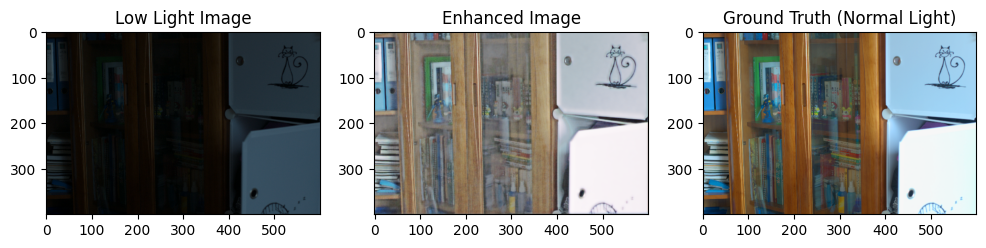

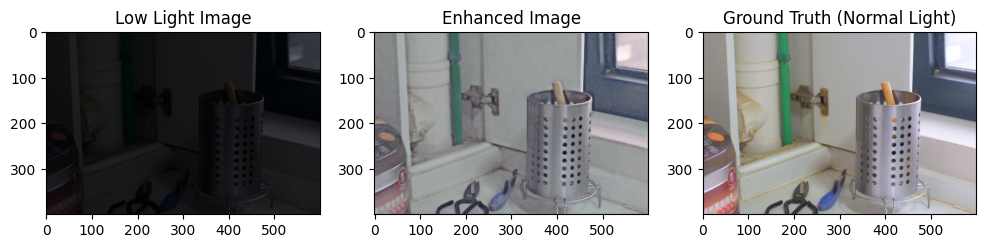

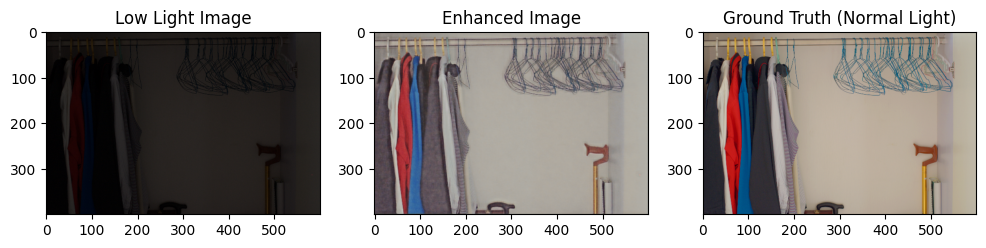

4/4 [==============================] - 1s 149ms/step
Hyperparameters: {'batch_size': 16, 'epochs': 50, 'learning_rate': 0.001}, MSE: 0.19453522562980652, PSNR: 5.984672572930757, SSIM: 0.2628868520259857
Epoch 1/50
25/25 [==============================] - 11s 334ms/step - loss: 0.0395 - accuracy: 0.5171 - val_loss: 0.2139 - val_accuracy: 0.4404
Epoch 2/50
25/25 [==============================] - 7s 268ms/step - loss: 0.0311 - accuracy: 0.5918 - val_loss: 0.2842 - val_accuracy: 0.1520
Epoch 3/50
25/25 [==============================] - 8s 310ms/step - loss: 0.0290 - accuracy: 0.5777 - val_loss: 0.0560 - val_accuracy: 0.4950
Epoch 4/50
25/25 [==============================] - 7s 269ms/step - loss: 0.0305 - accuracy: 0.6043 - val_loss: 0.0713 - val_accuracy: 0.5500
Epoch 5/50
25/25 [==============================] - 7s 269ms/step - loss: 0.0298 - accuracy: 0.6118 - val_loss: 0.0610 - val_accuracy: 0.1305
Epoch 6/50
25/25 [==============================] - 8s 303ms/step - loss: 0.0301 - ac

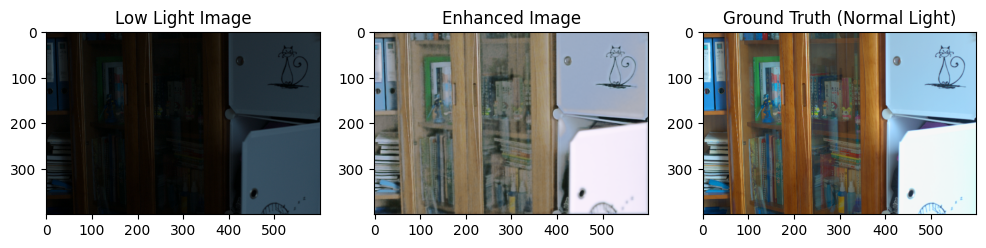

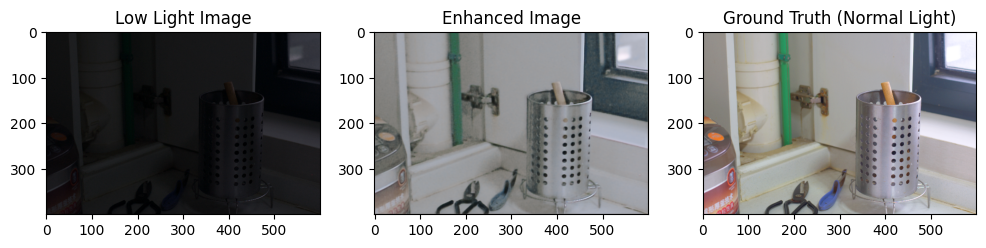

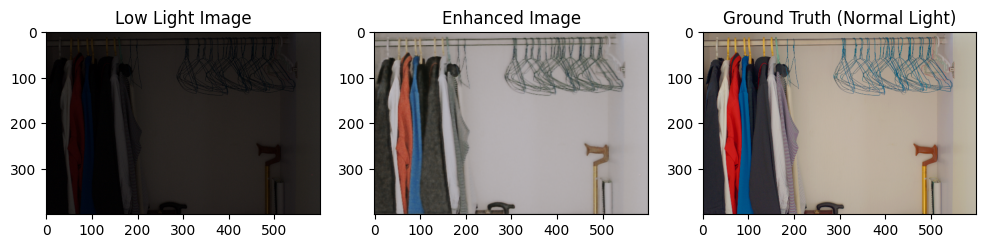

4/4 [==============================] - 1s 149ms/step
Hyperparameters: {'batch_size': 16, 'epochs': 50, 'learning_rate': 0.01}, MSE: 0.16743284463882446, PSNR: 5.527274315202215, SSIM: 0.2601652443408966
Epoch 1/100
25/25 [==============================] - 11s 335ms/step - loss: 0.0376 - accuracy: 0.5081 - val_loss: 0.0513 - val_accuracy: 0.4306
Epoch 2/100
25/25 [==============================] - 7s 266ms/step - loss: 0.0274 - accuracy: 0.5851 - val_loss: 0.0519 - val_accuracy: 0.5938
Epoch 3/100
25/25 [==============================] - 7s 269ms/step - loss: 0.0258 - accuracy: 0.6119 - val_loss: 0.0516 - val_accuracy: 0.4077
Epoch 4/100
25/25 [==============================] - 7s 268ms/step - loss: 0.0241 - accuracy: 0.6178 - val_loss: 0.0522 - val_accuracy: 0.3595
Epoch 5/100
25/25 [==============================] - 7s 266ms/step - loss: 0.0240 - accuracy: 0.6351 - val_loss: 0.0527 - val_accuracy: 0.3310
Epoch 6/100
25/25 [==============================] - 7s 269ms/step - loss: 0.0233

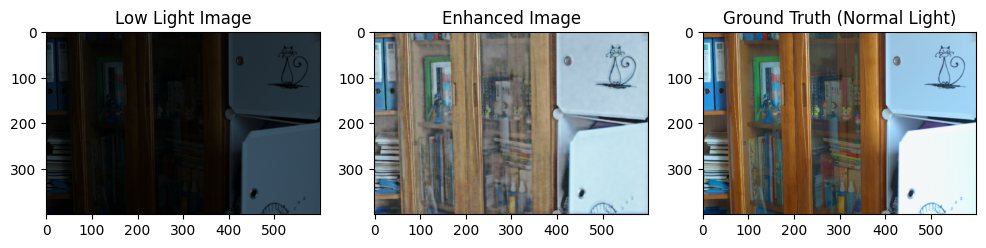

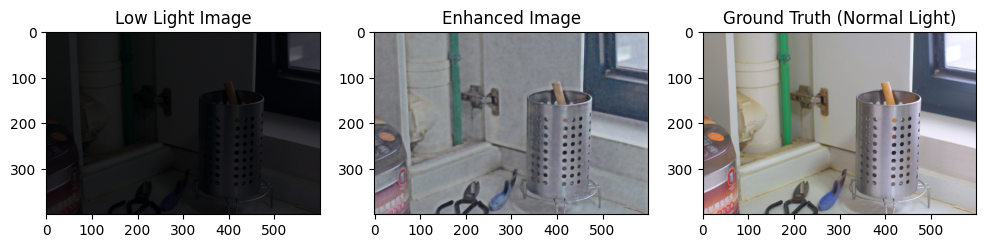

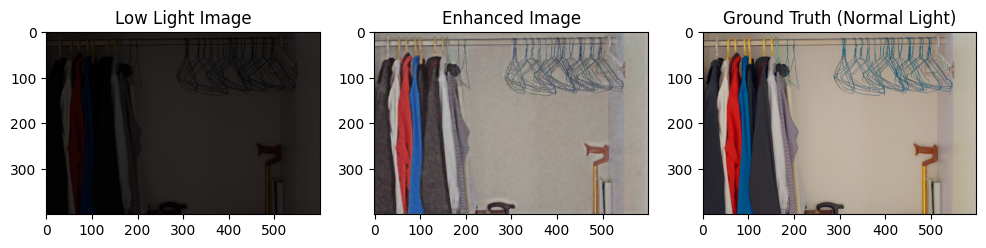

4/4 [==============================] - 0s 147ms/step
Hyperparameters: {'batch_size': 16, 'epochs': 100, 'learning_rate': 0.0001}, MSE: 0.17114879190921783, PSNR: 6.619162885949659, SSIM: 0.2721678912639618
Epoch 1/100
25/25 [==============================] - 11s 337ms/step - loss: 0.0315 - accuracy: 0.5336 - val_loss: 0.0562 - val_accuracy: 0.3167
Epoch 2/100
25/25 [==============================] - 7s 274ms/step - loss: 0.0246 - accuracy: 0.6372 - val_loss: 0.0555 - val_accuracy: 0.5712
Epoch 3/100
25/25 [==============================] - 7s 269ms/step - loss: 0.0253 - accuracy: 0.6667 - val_loss: 0.0574 - val_accuracy: 0.5606
Epoch 4/100
25/25 [==============================] - 8s 310ms/step - loss: 0.0241 - accuracy: 0.6609 - val_loss: 0.0542 - val_accuracy: 0.5613
Epoch 5/100
25/25 [==============================] - 7s 268ms/step - loss: 0.0227 - accuracy: 0.6752 - val_loss: 0.0557 - val_accuracy: 0.5615
Epoch 6/100
25/25 [==============================] - 8s 308ms/step - loss: 0.0

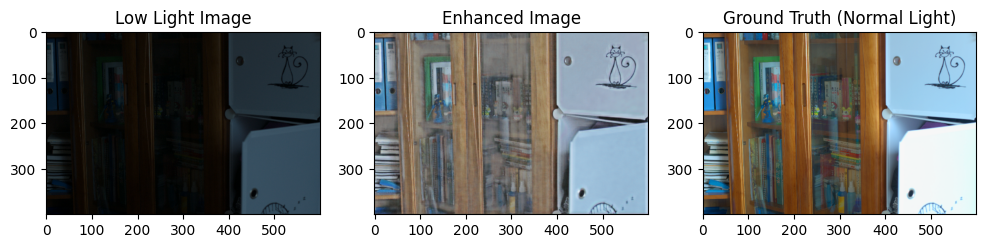

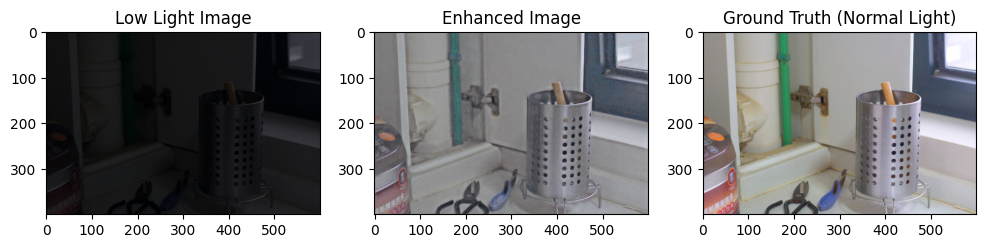

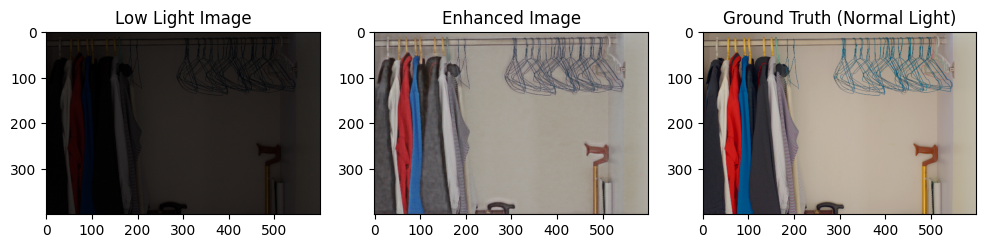

4/4 [==============================] - 1s 148ms/step
Hyperparameters: {'batch_size': 16, 'epochs': 100, 'learning_rate': 0.001}, MSE: 0.16814285516738892, PSNR: 6.510208409771972, SSIM: 0.27560287714004517
Epoch 1/100
25/25 [==============================] - 11s 336ms/step - loss: 0.0421 - accuracy: 0.4288 - val_loss: 0.3391 - val_accuracy: 0.3052
Epoch 2/100
25/25 [==============================] - 7s 272ms/step - loss: 0.0308 - accuracy: 0.5636 - val_loss: 0.2774 - val_accuracy: 0.3179
Epoch 3/100
25/25 [==============================] - 7s 273ms/step - loss: 0.0290 - accuracy: 0.5757 - val_loss: 0.1647 - val_accuracy: 0.3129
Epoch 4/100
25/25 [==============================] - 7s 274ms/step - loss: 0.0305 - accuracy: 0.6300 - val_loss: 0.0540 - val_accuracy: 0.5607
Epoch 5/100
25/25 [==============================] - 7s 273ms/step - loss: 0.0281 - accuracy: 0.6135 - val_loss: 0.0474 - val_accuracy: 0.4700
Epoch 6/100
25/25 [==============================] - 7s 273ms/step - loss: 0.0

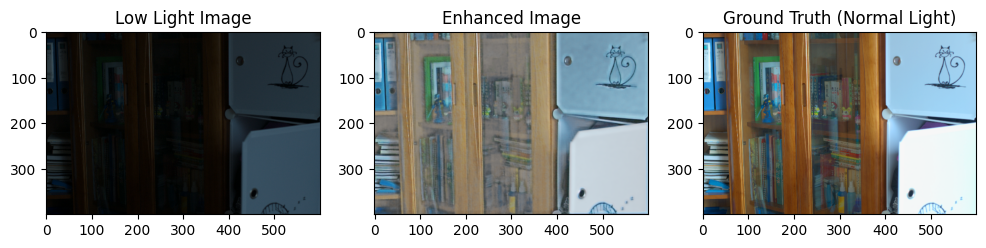

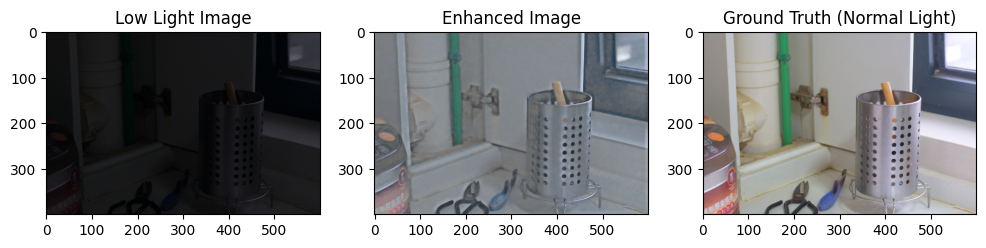

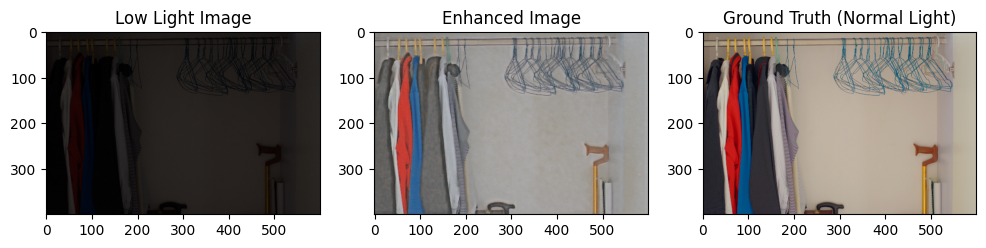

4/4 [==============================] - 1s 151ms/step
Hyperparameters: {'batch_size': 16, 'epochs': 100, 'learning_rate': 0.01}, MSE: 0.17928388714790344, PSNR: 7.15037821816316, SSIM: 0.2969406545162201


In [ ]:
param_grid = {
    'learning_rate': [0.0001, 0.001, 0.01],
    'epochs': [50, 100],
    'batch_size': [8, 16]
}

# Generate all combinations of hyperparameters
param_combinations = list(ParameterGrid(param_grid))

# Example: Evaluate the model with different hyperparameter combinations
for params in param_combinations:
    results = evaluate_fmbcnn_cnn_model_(train_low_light_images, val_low_light_images, params)
    print(f"Hyperparameters: {results['params']}, MSE: {results['mse']}, PSNR: {results['psnr']}, SSIM: {results['ssim']}")

In [ ]:
K.clear_session()

In [ ]:
def build_generator(input_shape, generator_activation):
    inputs = tf.keras.Input(shape=input_shape)

    # Encoder
    x = layers.Conv2D(64, (3, 3), padding='same', activation= generator_activation)(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(128, (3, 3), padding='same', activation=generator_activation)(x)
    x = layers.BatchNormalization()(x)

    # Bottleneck - Residual Blocks with Batch Normalization
    for _ in range(6):
        x = residual_block(x, 128, generator_activation)

    # Decoder
    x = layers.Conv2D(64, (3, 3), padding='same', activation=generator_activation)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(3, (3, 3), padding='same', activation='sigmoid')(x)

    outputs = layers.Add()([x, inputs])

    generator = tf.keras.Model(inputs, outputs, name='generator')
    return generator

# Define the discriminator model
def build_discriminator(input_shape, discriminator_activation):
    inputs = tf.keras.Input(shape=input_shape)

    x = layers.Conv2D(64, (3, 3), padding='same', activation=discriminator_activation)(inputs)
    x = layers.Conv2D(128, (3, 3), padding='same', activation=discriminator_activation)(x)

    x = layers.Flatten()(x)
    x = layers.Dense(1, activation='sigmoid')(x)

    discriminator = tf.keras.Model(inputs, x, name='discriminator')
    return discriminator

# Define a residual block
def residual_block(x, filters, generator_activation):
    shortcut = x

    x = layers.Conv2D(filters, (3, 3), padding='same', activation=generator_activation)(x)
    x = layers.Conv2D(filters, (3, 3), padding='same')(x)

    x = layers.Add()([x, shortcut])  # Skip connection
    x = layers.Activation(generator_activation)(x)

    return x

input_shape = (400, 600, 3)

In [ ]:
def save_generated_images(low_light_images, high_light_images, generated_images, epoch):
    num_images = len(low_light_images)
    min_length = min(len(low_light_images), len(high_light_images), len(generated_images))

    print(f"Num Images: {num_images}")
    print(f"Min Length: {min_length}")

    for i in range(min_length):
        low_light = low_light_images[i]
        high_light = high_light_images[i]
        generated = (generated_images[i] * 255).astype(np.uint8)

        print(f"Index: {i}")

        plt.figure(figsize=(15, 5))

        plt.subplot(1, 3, 1)
        plt.imshow(low_light)
        plt.title('Low-Light Image')
        plt.axis('off')

        plt.subplot(1, 3, 2)
        plt.imshow(high_light)
        plt.title('High-Light Image')
        plt.axis('off')

        plt.subplot(1, 3, 3)
        plt.imshow(generated)
        plt.title('Generated Image')
        plt.axis('off')
        plt.show()

In [ ]:
# Function to build the GAN model
from tensorflow.keras.models import load_model

def build_gan(learning_rate, generator_activation, discriminator_activation):

# Load the saved model
  denoised_model = load_model("/content/drive/MyDrive/fmbcnn_with_skip_connections_model.h5")
  # Build the generator (use the denoising CNN as the generator)
  generator = denoised_model
  generator.trainable = False  # Freeze the denoising CNN during GAN training
  # generator = build_generator(input_shape, generator_activation)

  discriminator = build_discriminator(input_shape, discriminator_activation)
  discriminator.compile(loss='binary_crossentropy', optimizer=Adam(learning_rate=learning_rate, beta_1=0.5), metrics=['accuracy'])

  # Compile the GAN
  discriminator.trainable = False
  gan_input = tf.keras.Input(shape=(400, 600, 3))

  # Generate denoised images using the denoising CNN (generator)
  x_denoised = denoised_model(gan_input)
  # Generate enhanced images using the GAN's generator
  x_enhanced = generator(x_denoised)

  # x = generator(gan_input)
  gan_output = discriminator(x_enhanced)

  gan = Model(gan_input, gan_output)
  gan.compile(loss='binary_crossentropy', optimizer=Adam(learning_rate=learning_rate, beta_1=0.5))
  test_loss = gan_model.evaluate(test_low_light_images, test_normal_light_images)
  priint("Test Loss: ", test_loss)

  return gan, generator, discriminator

In [ ]:
def train_gan(gan, x_train_low, x_train_high, epochs, batch_size, generator, discriminator):
  # Train the GAN
  for epoch in range(epochs):
      for _ in range(len(x_train_low) // batch_size):
          # Sample a batch of low-light images
          idx = np.random.randint(0, len(x_train_low), batch_size)
          low_batch = x_train_low[idx]

          # Generate corresponding high-light images using the generator
          generated_high_batch = generator.predict(low_batch)

          # Create labels for real and generated images
          real_labels = np.ones((batch_size, 1))
          fake_labels = np.zeros((batch_size, 1))

          # Train the discriminator on real images
          d_loss_real = discriminator.train_on_batch(x_train_high[idx], real_labels)

          # Train the discriminator on generated images
          d_loss_fake = discriminator.train_on_batch(generated_high_batch, fake_labels)

          # Compute the total discriminator loss
          d_loss = 0.5 * np.add(d_loss_real, d_loss_fake)

          # Train the generator to fool the discriminator
          g_loss = gan.train_on_batch(low_batch, real_labels)

          print(f"Epoch {epoch + 1}/{epochs} [D loss: {d_loss[0]} | D accuracy: {100 * d_loss[1]}] [G loss: {g_loss}]")

      if (epoch + 1) % 5 == 0:
        generated_images = generator.predict(val_low_light_images[:4])
        # Ensure the correct mapping of generated images to low and high images
        mapped_generated_images = generated_images[:len(val_low_light_images[:15])]

        # Now you can use the save_generated_images function to save and display the comparison
        print("x_val_low: ",len(val_low_light_images[:15]))
        save_generated_images(val_low_light_images[:15], val_normal_light_images[:15], mapped_generated_images, epoch + 1)

In [ ]:
# Function to evaluate the GAN model with different hyperparameter combinations
def evaluate_gan_model(x_train_low, x_train_high, x_val_low, x_val_high, params):
    # latent_dim = params['latent_dim']
    learning_rate = params['learning_rate']
    generator_activation = params['generator_activation']
    discriminator_activation = params['discriminator_activation']
    epochs = params['epochs']
    batch_size = params['batch_size']

    # Build the GAN model
    gan, generator, discriminator = build_gan(learning_rate, generator_activation, discriminator_activation)

    # Train the GAN model
    train_gan(gan, x_train_low, x_train_high, epochs, batch_size, generator, discriminator)

    # Generate images using the trained GAN
    generated_images = generator.predict(x_val_low)

    # Evaluate generated images (replace this with your evaluation metrics)
    mse = np.mean(np.square(x_val_high - generated_images))
    psnr = peak_signal_noise_ratio(x_val_high[0], generated_images[0], data_range=generated_images[0].max())
    ssim_index = structural_similarity(x_val_high[0], generated_images[0], multichannel=True)

    return {'params': params, 'mse': mse, 'psnr': psnr, 'ssim': ssim_index}

In [ ]:
K.clear_session()

In [ ]:
from keras.layers import ReLU, GlobalAveragePooling2D
# Specify the hyperparameter grid for search
param_grid = {
    'learning_rate': [0.01, 0.001, 0.0001],
    'epochs': [50],
    'batch_size': [8],
    'generator_activation': ['relu'],
    'discriminator_activation': ['relu']
}

# Generate all combinations of hyperparameters
param_combinations = list(ParameterGrid(param_grid))

# Example: Evaluate the GAN model with different hyperparameter combinations
for params in param_combinations:
    results = evaluate_gan_model(train_low_light_images, train_normal_light_images, val_low_light_images, val_normal_light_images, params)
    print(f"Hyperparameters: {results['params']}, MSE: {results['mse']}, PSNR: {results['psnr']}, SSIM: {results['ssim']}")